# **Random Forest**


--- Training and Evaluating Random Forest ---
Random Forest - Accuracy: 0.8889
Random Forest - Precision: 0.9000
Random Forest - Recall: 0.9000
Random Forest - F1 Score: 0.8889


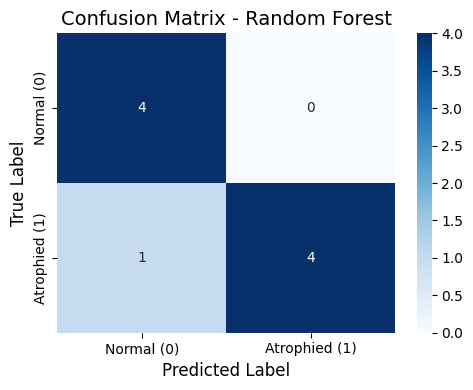


--- Feature Importance (Random Forest) ---
            Feature  Importance
13  TC09000418.hg.1    0.098822
32  TC06002840.hg.1    0.072529
46  TC06003153.hg.1    0.063495
0   TC18000202.hg.1    0.060025
42  TC17001019.hg.1    0.058565
37  TC04000542.hg.1    0.055891
38  TC15001685.hg.1    0.048949
7   TC12002953.hg.1    0.044637
14  TC10002665.hg.1    0.039871
3   TC01002613.hg.1    0.039820


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load and Prepare Data ---
file_path = '/content/drive/MyDrive/Mini/36.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: The file was not found at {file_path}")
    exit()

identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Split data for this model's training and evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

# Scale data
scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

# --- Model Training and Evaluation ---
print("\n--- Training and Evaluating Random Forest ---")

# Define the Random Forest model (ensure parameters are consistent)
# Using class_weight='balanced' as per your previous setup
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train the model
rf_model.fit(X_scaled_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_scaled_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, average='macro', zero_division=0)

print(f"Random Forest - Accuracy: {accuracy_rf:.4f}")
print(f"Random Forest - Precision: {precision_rf:.4f}")
print(f"Random Forest - Recall: {recall_rf:.4f}")
print(f"Random Forest - F1 Score: {f1_rf:.4f}")

# Display Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Atrophied (1)'],
            yticklabels=['Normal (0)', 'Atrophied (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Random Forest', fontsize=14)
plt.tight_layout()
plt.show()

# --- Feature Importance ---
print("\n--- Feature Importance (Random Forest) ---")
importances_rf = rf_model.feature_importances_
feature_importances_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': importances_rf})
feature_importances_rf = feature_importances_rf.sort_values('Importance', ascending=False)
print(feature_importances_rf.head(10)) # Display top 10 features

# **SVM**


--- Training and Evaluating SVM ---
Best hyperparameters: {'C': 0.01, 'kernel': 'linear'}
SVM - Accuracy: 1.0000
SVM - Precision: 1.0000
SVM - Recall: 1.0000
SVM - F1 Score: 1.0000


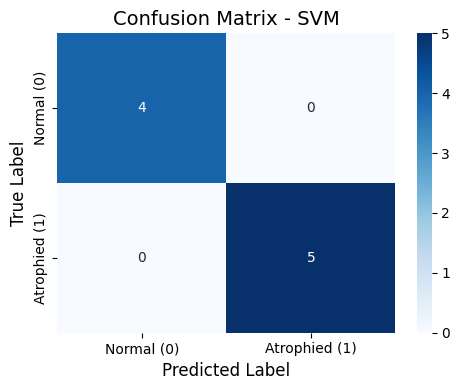


--- Feature Importance (SVM) ---
            Feature  Coefficient  Abs_Coefficient
37  TC04000542.hg.1     0.079775         0.079775
0   TC18000202.hg.1     0.064460         0.064460
13  TC09000418.hg.1     0.063569         0.063569
1   TC02001974.hg.1    -0.062776         0.062776
9   TC20000685.hg.1    -0.056950         0.056950
11  TC09001434.hg.1     0.053380         0.053380
32  TC06002840.hg.1     0.050199         0.050199
58  TC15001458.hg.1     0.050058         0.050058
10  TC06003411.hg.1    -0.045663         0.045663
17  TC02000466.hg.1    -0.042925         0.042925


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load and Prepare Data ---
file_path = '/content/drive/MyDrive/Mini/36.csv'
df = pd.read_csv(file_path)

identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Split data for this model's training and evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Scale data
scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

# --- Model Training and Evaluation ---
print("\n--- Training and Evaluating SVM ---")

# Modified: Stronger Regularization and Linear Kernel and Gridsearch
svm_model = SVC(probability=True, random_state=42, class_weight='balanced')

# Define the parameter grid
param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.001, 0.01, 0.1, 1, 10],
}

# Define cross-validation strategy
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# Perform Grid Search Cross-Validation
grid_search = GridSearchCV(svm_model, param_grid, scoring='accuracy', cv=cv, n_jobs=-1, verbose=0)
grid_search.fit(X_scaled_train, y_train)

# Get the best estimator from GridSearchCV
best_svm = grid_search.best_estimator_
print("Best hyperparameters:", grid_search.best_params_)

# Make predictions
y_pred_svm = best_svm.predict(X_scaled_test)

# Evaluate the model
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average='macro', zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, average='macro', zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, average='macro', zero_division=0)

print(f"SVM - Accuracy: {accuracy_svm:.4f}")
print(f"SVM - Precision: {precision_svm:.4f}")
print(f"SVM - Recall: {recall_svm:.4f}")
print(f"SVM - F1 Score: {f1_svm:.4f}")

# Display Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Atrophied (1)'],
            yticklabels=['Normal (0)', 'Atrophied (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - SVM', fontsize=14)
plt.tight_layout()
plt.show()

# Feature Importance (based on coefficients - only applicable for linear kernel)
print("\n--- Feature Importance (SVM) ---")
if best_svm.kernel == 'linear':
    svm_coef = best_svm.coef_[0]
    feature_importances = pd.DataFrame({'Feature': feature_cols, 'Coefficient': svm_coef})
    feature_importances['Abs_Coefficient'] = np.abs(feature_importances['Coefficient'])
    feature_importances = feature_importances.sort_values('Abs_Coefficient', ascending=False)
    print(feature_importances.head(10))
else:
    print("Feature importance not directly available for RBF kernel.  Consider using SHAP values or switching to a linear kernel.")

# **XGBoost**


--- Training and Evaluating XGBoost ---


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [18:41:53] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost - Accuracy: 0.8889
XGBoost - Precision: 0.9000
XGBoost - Recall: 0.9000
XGBoost - F1 Score: 0.8889


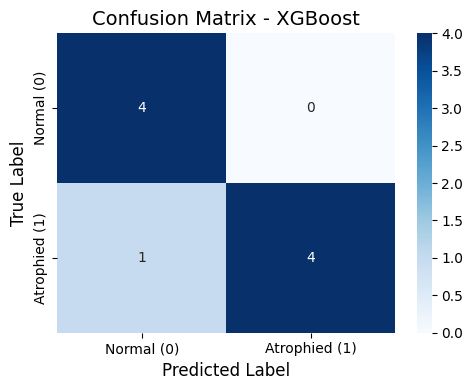


--- Feature Importance (XGBoost) ---
            Feature  Importance
12  TC10000836.hg.1    0.103053
20  TC05001248.hg.1    0.102532
13  TC09000418.hg.1    0.090116
30  TC06000518.hg.1    0.088193
3   TC01002613.hg.1    0.087760
15  TC18000033.hg.1    0.076510
37  TC04000542.hg.1    0.064257
11  TC09001434.hg.1    0.056432
46  TC06003153.hg.1    0.050702
8   TC08000447.hg.1    0.047000


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load and Prepare Data ---
file_path = '/content/drive/MyDrive/Mini/36.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: The file was not found at {file_path}")
    exit()

identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Split data for this model's training and evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

# Scale data
scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

# --- Model Training and Evaluation ---
print("\n--- Training and Evaluating XGBoost ---")

# Calculate scale_pos_weight for XGBoost if classes are imbalanced
if (y_train == 1).sum() > 0 and (y_train == 0).sum() > 0:
    xgb_scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
else:
    xgb_scale_pos_weight = 1

# Modified: Adjusted Parameters for Improved Performance
# Reduced learning_rate, increased n_estimators, added regularization
xgb_model = XGBClassifier(
    n_estimators=200,  # Increased n_estimators for potentially better learning
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=xgb_scale_pos_weight,
    learning_rate=0.05,  # Reduced learning rate to prevent overfitting
    max_depth=3,         # Reduced Max Depth,
    reg_alpha=0.1,        # L1 regularization (experiment)
    reg_lambda=1,         # L2 regularization (experiment)
    subsample=0.8,        # Adding subsample
    colsample_bytree=0.8   # Adding colsample_bytree

)

# Train the model
xgb_model.fit(X_scaled_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_scaled_test)

# Evaluate the model
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb, average='macro', zero_division=0)
recall_xgb = recall_score(y_test, y_pred_xgb, average='macro', zero_division=0)
f1_xgb = f1_score(y_test, y_pred_xgb, average='macro', zero_division=0)

print(f"XGBoost - Accuracy: {accuracy_xgb:.4f}")
print(f"XGBoost - Precision: {precision_xgb:.4f}")
print(f"XGBoost - Recall: {recall_xgb:.4f}")
print(f"XGBoost - F1 Score: {f1_xgb:.4f}")

# Display Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Atrophied (1)'],
            yticklabels=['Normal (0)', 'Atrophied (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - XGBoost', fontsize=14)
plt.tight_layout()
plt.show()

# --- Feature Importance ---
print("\n--- Feature Importance (XGBoost) ---")
# Get feature importances
importances_xgb = xgb_model.feature_importances_

# Create a DataFrame to store feature importances
feature_importances_xgb = pd.DataFrame({'Feature': feature_cols, 'Importance': importances_xgb})

# Sort by importance
feature_importances_xgb = feature_importances_xgb.sort_values('Importance', ascending=False)
print(feature_importances_xgb.head(10)) # Display top 10 features

# **Elastic Net**


--- Training and Evaluating Elastic Net ---
Best hyperparameters: {'C': 0.001, 'l1_ratio': 0.0}
Elastic Net - Accuracy: 0.8889
Elastic Net - Precision: 0.9000
Elastic Net - Recall: 0.9000
Elastic Net - F1 Score: 0.8889


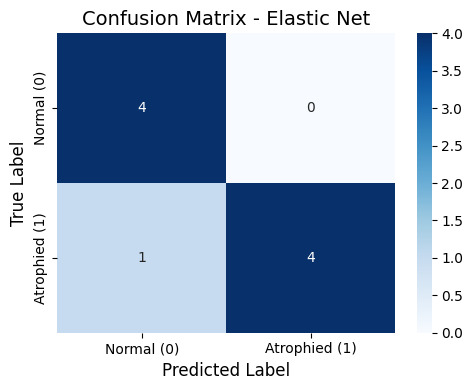


--- Feature Importance (Elastic Net) ---
            Feature  Coefficient  Abs_Coefficient
37  TC04000542.hg.1     0.009622         0.009622
13  TC09000418.hg.1     0.009544         0.009544
11  TC09001434.hg.1     0.009509         0.009509
20  TC05001248.hg.1     0.009020         0.009020
41  TC12003246.hg.1    -0.008795         0.008795
2   TC20000246.hg.1    -0.008721         0.008721
8   TC08000447.hg.1     0.008680         0.008680
31  TC18000042.hg.1     0.008667         0.008667
12  TC10000836.hg.1     0.008576         0.008576
45  TC05001247.hg.1     0.008521         0.008521


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, LogisticRegression # Renamed
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load and Prepare Data ---
file_path = '/content/drive/MyDrive/Mini/36.csv'
df = pd.read_csv(file_path)

identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Split data for this model's training and evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Scale data
scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

# --- Model Training and Evaluation ---
print("\n--- Training and Evaluating Elastic Net ---")

# Replaced ElasticNet() with LogisticRegression() and added penalty='elasticnet'
# Elastic-Net for classification involves using a logistic regression with elastic net regularization.
# This involves finding the best combination of L1 and L2 regularization using the l1_ratio parameter.
elastic_net_model = LogisticRegression(penalty='elasticnet', solver='saga', random_state=42, class_weight='balanced', max_iter=10000)

# Define parameter grid for GridSearchCV
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10],            # Inverse of regularization strength
    'l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0]  # L1 regularization ratio
}

# Define cross-validation strategy
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# Perform GridSearchCV
grid_search = GridSearchCV(elastic_net_model, param_grid=param_grid, scoring='accuracy', cv=cv, n_jobs=-1, verbose=0)
grid_search.fit(X_scaled_train, y_train)

# Get best estimator
best_elastic_net = grid_search.best_estimator_
print("Best hyperparameters:", grid_search.best_params_)

# Make predictions
y_pred_elastic = best_elastic_net.predict(X_scaled_test)

# Evaluate the model
accuracy_elastic = accuracy_score(y_test, y_pred_elastic)
precision_elastic = precision_score(y_test, y_pred_elastic, average='macro', zero_division=0)
recall_elastic = recall_score(y_test, y_pred_elastic, average='macro', zero_division=0)
f1_elastic = f1_score(y_test, y_pred_elastic, average='macro', zero_division=0)

print(f"Elastic Net - Accuracy: {accuracy_elastic:.4f}")
print(f"Elastic Net - Precision: {precision_elastic:.4f}")
print(f"Elastic Net - Recall: {recall_elastic:.4f}")
print(f"Elastic Net - F1 Score: {f1_elastic:.4f}")

# Display Confusion Matrix
cm_elastic = confusion_matrix(y_test, y_pred_elastic)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_elastic, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Atrophied (1)'],
            yticklabels=['Normal (0)', 'Atrophied (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Elastic Net', fontsize=14)
plt.tight_layout()
plt.show()

# --- Feature Importance ---
print("\n--- Feature Importance (Elastic Net) ---")
# Feature Importance (based on coefficients)
coefficients = best_elastic_net.coef_[0]
feature_importances = pd.DataFrame({'Feature': feature_cols, 'Coefficient': coefficients})
feature_importances['Abs_Coefficient'] = np.abs(feature_importances['Coefficient'])
feature_importances = feature_importances.sort_values('Abs_Coefficient', ascending=False)
print(feature_importances.head(10))

# **Random Forest**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Accuracy: 0.9167
Precision: 0.9350
Recall: 0.9181
F1_score: 0.9135
Roc_auc: 0.9926


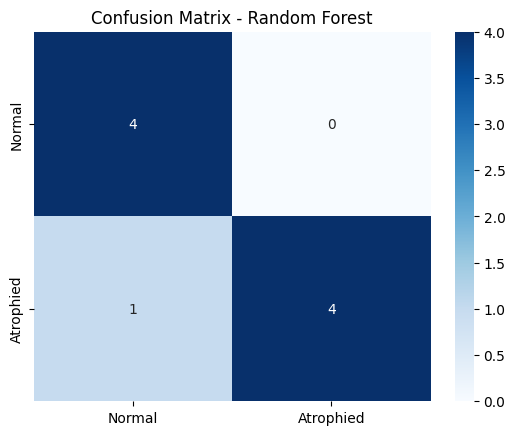

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Mount Google Drive (if in Colab)
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset
file_path = '/content/drive/MyDrive/Mini/36.csv'
df = pd.read_csv(file_path)

# Prepare Data
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Model definition
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Cross-validation setup
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro', zero_division=0),
    'recall': make_scorer(recall_score, average='macro', zero_division=0),
    'f1_score': make_scorer(f1_score, average='macro', zero_division=0),
    'roc_auc': 'roc_auc'
}
rskf = RepeatedStratifiedKFold(n_splits=6, n_repeats=5, random_state=42)

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Cross-validation
cv_scores = cross_validate(rf_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Atrophied'], yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - Random Forest')
plt.show()


# **XGBoost**

Accuracy: 0.8889
Precision: 0.9086
Recall: 0.8917
F1_score: 0.8850
Roc_auc: 0.9370


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [18:49:33] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


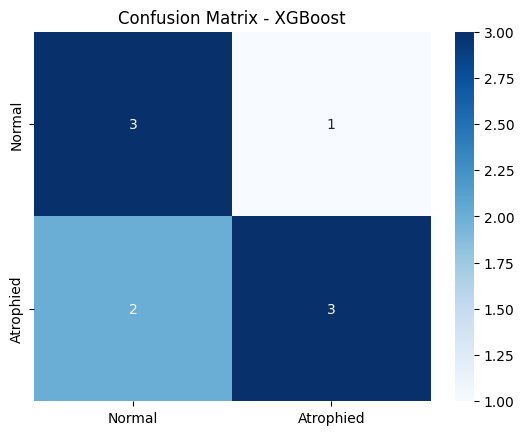

In [ ]:
from xgboost import XGBClassifier

# Handle imbalance
xgb_scale_pos_weight = (y == 0).sum() / (y == 1).sum()

# Model definition
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=xgb_scale_pos_weight
)

# Cross-validation
cv_scores = cross_validate(xgb_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Atrophied'], yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - XGBoost')
plt.show()


# **SVM**

Accuracy: 0.9778
Precision: 0.9833
Recall: 0.9778
F1_score: 0.9771
Roc_auc: 1.0000


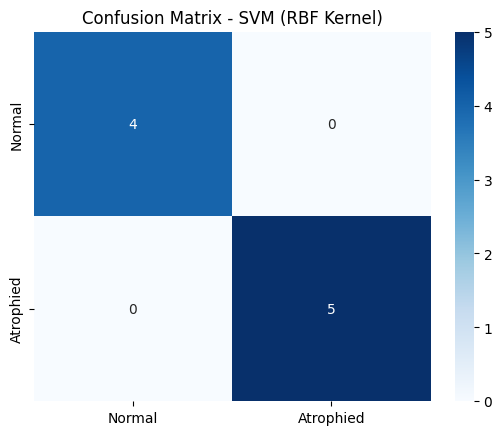

In [ ]:
from sklearn.svm import SVC

# Model definition
svm_model = SVC(
    probability=True,
    random_state=42,
    class_weight='balanced',
    kernel='rbf',
    C=1.0
)

# Cross-validation
cv_scores = cross_validate(svm_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Atrophied'], yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - SVM (RBF Kernel)')
plt.show()
